# Georeferencias

In [46]:
!pip install -q geopandas fiona pyogrio scikit-learn matplotlib seaborn

Sectores catastrales urbanos procesados: 1,049

--- Tabla de Selección Formal de k (Variables Delictivas) ---


,k,Inercia (Codo),Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,2442.6,0.4076,0.9942,751.6
1,3,1911.8,0.3536,1.1384,624.9
2,4,1663.7,0.3290,1.3003,530.2
3,5,1483.1,0.3310,1.2472,477.4
4,6,1309.6,0.3259,1.1390,459.8
5,7,1160.9,0.3244,0.9891,454.0
6,8,1067.7,0.3209,1.0046,435.7
7,9,979.6,0.3103,1.0919,426.9
8,10,903.3,0.3129,1.0890,420.8


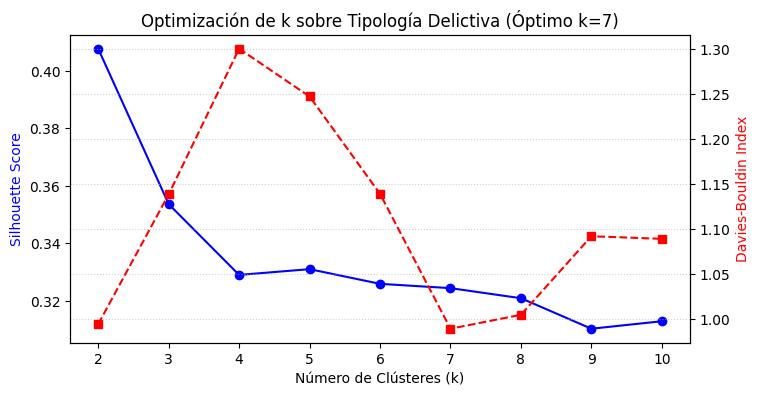


--- Caracterización de los 7 Clústeres Ordenados por Severidad ---


,sectores,prom_hurtos,prom_homicidios,prom_lesiones,score_base
cluster_delictivo,,,,,
0,304,167.16,68.26,20.34,15.0
1,328,671.55,277.82,107.31,28.0
2,198,887.12,234.74,163.03,42.0
3,1,467.00,1538.00,58.00,55.0
4,150,1678.40,557.84,274.53,68.0
5,3,1348.33,223.67,1121.67,80.0
6,65,2057.15,566.83,467.68,92.0


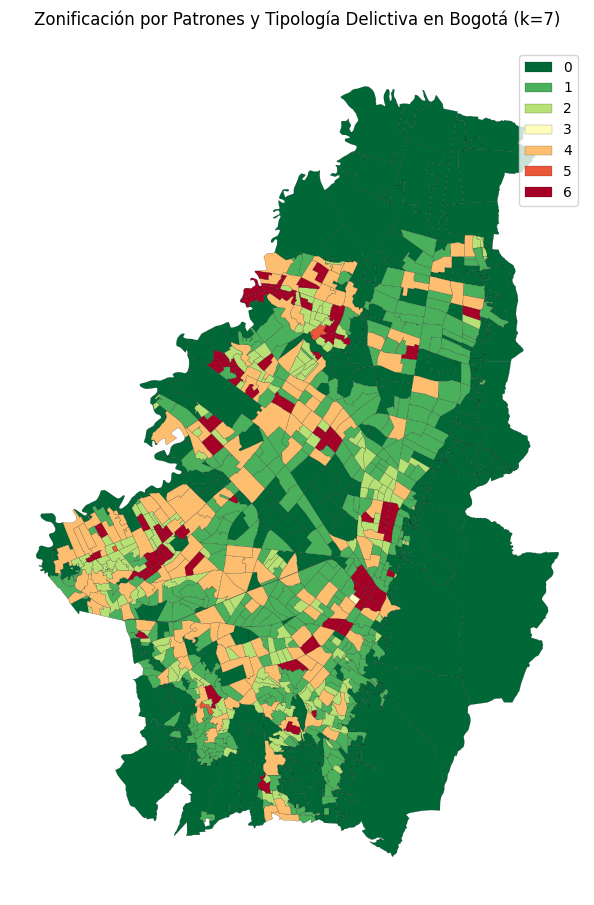

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pyproj
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# 1. Cargar capa georreferenciada y reproyectar a coordenadas planas métricas (Bogotá EPSG:3116)
path_gpkg = "Data/IRSCAT.gpkg"
gdf_raw = gpd.read_file(path_gpkg)
gdf_metric = gdf_raw.to_crs(epsg=3116)

# Filtrar el casco urbano (excluir Sumapaz y zonas rurales extremas con Norte <= 990,000)
centroides_y = gdf_metric.geometry.centroid.y
gdf_urbano = gdf_metric[centroides_y > 990000].copy()
print(f"Sectores catastrales urbanos procesados: {len(gdf_urbano):,}")

# 2. Extracción de variables delictivas recientes (2023-2025)
cols_hom = [c for c in gdf_urbano.columns if c.startswith('CMH') and any(c.endswith(y) for y in ['23CONT', '24CONT', '25CONT']) and not c.startswith('CMHC')]
cols_hur = [c for c in gdf_urbano.columns if c.startswith('CMR') and any(c.endswith(y) for y in ['23CONT', '24CONT', '25CONT'])]
cols_les = [c for c in gdf_urbano.columns if c.startswith('CMN') and any(c.endswith(y) for y in ['23CONT', '24CONT', '25CONT'])]

gdf_urbano['homicidios_totales'] = gdf_urbano[cols_hom].sum(axis=1)
gdf_urbano['hurtos_totales'] = gdf_urbano[cols_hur].sum(axis=1)
gdf_urbano['lesiones_totales'] = gdf_urbano[cols_les].sum(axis=1)
gdf_urbano['delitos_totales'] = gdf_urbano['homicidios_totales'] + gdf_urbano['hurtos_totales'] + gdf_urbano['lesiones_totales']

# Normalización por área (densidad por km²) para evitar sesgo por tamaño del polígono
gdf_urbano['area_km2'] = (gdf_urbano.geometry.area / 1e6).replace(0, 0.001)
gdf_urbano['densidad_hurtos'] = gdf_urbano['hurtos_totales'] / gdf_urbano['area_km2']
gdf_urbano['densidad_homicidios'] = gdf_urbano['homicidios_totales'] / gdf_urbano['area_km2']
gdf_urbano['densidad_lesiones'] = gdf_urbano['lesiones_totales'] / gdf_urbano['area_km2']

features_delictivas = ['densidad_hurtos', 'densidad_homicidios', 'densidad_lesiones', 'delitos_totales']
scaler = StandardScaler()
X_delictivo = scaler.fit_transform(gdf_urbano[features_delictivas].fillna(0))

# 3. Evaluación formal de k (Método del Codo, Silhouette, Davies-Bouldin y Calinski-Harabasz)
eval_k = []
for k in range(2, 11):
    km_temp = KMeans(n_clusters=k, init='k-means++', n_init=15, random_state=42)
    labels_temp = km_temp.fit_predict(X_delictivo)
    eval_k.append({
        'k': k,
        'Inercia (Codo)': round(km_temp.inertia_, 1),
        'Silhouette': round(silhouette_score(X_delictivo, labels_temp), 4),
        'Davies-Bouldin': round(davies_bouldin_score(X_delictivo, labels_temp), 4),
        'Calinski-Harabasz': round(calinski_harabasz_score(X_delictivo, labels_temp), 1)
    })

df_eval_k = pd.DataFrame(eval_k)
print("\n--- Tabla de Selección Formal de k (Variables Delictivas) ---")
display(df_eval_k)

# Gráfica de selección de k
fig, ax1 = plt.subplots(figsize=(8, 4))
ax2 = ax1.twinx()
ax1.plot(df_eval_k['k'], df_eval_k['Silhouette'], 'b-o', label='Silhouette (Mayor mejor)')
ax2.plot(df_eval_k['k'], df_eval_k['Davies-Bouldin'], 'r--s', label='Davies-Bouldin (Menor mejor)')
ax1.set_xlabel('Número de Clústeres (k)')
ax1.set_ylabel('Silhouette Score', color='b')
ax2.set_ylabel('Davies-Bouldin Index', color='r')
plt.title("Optimización de k sobre Tipología Delictiva (Óptimo k=7)")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

# 4. Entrenamiento definitivo con k = 7 y ordenamiento por severidad (0 = más seguro, 6 = más crítico)
k_optimo = 7
km_final = KMeans(n_clusters=k_optimo, init='k-means++', n_init=15, random_state=42)
gdf_urbano['cluster_raw'] = km_final.fit_predict(X_delictivo)

# Ordenar etiquetas de clúster de menor a mayor peligrosidad promedio para consistencia en la App
severidad_orden = gdf_urbano.groupby('cluster_raw')['delitos_totales'].mean().sort_values().index
mapa_orden = {old_label: new_label for new_label, old_label in enumerate(severidad_orden)}
gdf_urbano['cluster_delictivo'] = gdf_urbano['cluster_raw'].map(mapa_orden)

#Asignar puntaje base de riesgo (escala 15 a 90) según el clúster ordenado
scores_base_map = {0: 15.0, 1: 28.0, 2: 42.0, 3: 55.0, 4: 68.0, 5: 80.0, 6: 92.0}
gdf_urbano['score_base_cluster'] = gdf_urbano['cluster_delictivo'].map(scores_base_map)

resumen_k7 = gdf_urbano.groupby('cluster_delictivo').agg(
    sectores=('CMNOMSCAT', 'count'),
    prom_hurtos=('hurtos_totales', 'mean'),
    prom_homicidios=('homicidios_totales', 'mean'),
    prom_lesiones=('lesiones_totales', 'mean'),
    score_base=('score_base_cluster', 'first')
).round(2)

print("\n--- Caracterización de los 7 Clústeres Ordenados por Severidad ---")
display(resumen_k7)

# 5. Mapa de zonificación por tipología delictiva (k=7)
fig, ax = plt.subplots(figsize=(9, 11))
gdf_urbano.plot(column='cluster_delictivo', categorical=True, legend=True, cmap='RdYlGn_r', edgecolor='black', linewidth=0.12, ax=ax)
plt.title("Zonificación por Patrones y Tipología Delictiva en Bogotá (k=7)", fontsize=12)
plt.axis('off')
plt.show()

# 6. Convertir centroides de cada sector a Lat/Lon (WGS84) para búsqueda GPS en la App
transformer = pyproj.Transformer.from_crs("EPSG:3116", "EPSG:4326", always_xy=True)
lons, lats = transformer.transform(gdf_urbano.geometry.centroid.x.values, gdf_urbano.geometry.centroid.y.values)
gdf_urbano['lat'] = lats
gdf_urbano['lon'] = lons

# Datos medicina legal

In [ ]:
from scipy import stats

# 1. Cargar dataset de Violencia Interpersonal
path_violencia = "Data/Violencia_interpersonal_Colombia.csv"
df_vio_raw = pd.read_csv(path_violencia, low_memory=False)

# 2. Auditoría formal para descarte de columnas (Varianza, Completitud y Target Leakage)
auditoria_cols = []
for col in df_vio_raw.columns:
    serie = df_vio_raw[col].astype(str)
    no_info = serie.str.contains('sin info|no report|no aplica|nan|none', case=False, na=True).sum()
    pct_no_info = round((no_info / len(df_vio_raw)) * 100, 2)
    top_pct = round(serie.value_counts(normalize=True).iloc[0] * 100, 2) if len(serie) > 0 else 100.0

    col_l = col.lower()
    if col in ['Sexo de la victima', 'Ciclo Vital']:
        estado, motivo = "RETENIDA", "Predictiva previa válida (alta completitud y entropía)"
    elif any(k in col_l for k in ['mecanismo', 'lesion', 'incapacidad', 'agresor', 'arma']):
        estado, motivo = "DESCARTADA", "Fuga de Información (Target Leakage - post-evento)"
    elif any(k in col_l for k in ['año', 'mes', 'dia', 'hora']):
        estado, motivo = "DESCARTADA", "Redundancia temporal (modelada en NUSE 123)"
    elif pct_no_info > 30.0:
        estado, motivo = "DESCARTADA", f"Incompletitud crítica ({pct_no_info}% sin información)"
    else:
        estado, motivo = "DESCARTADA", f"Varianza cuasi-nula / Redundante ({top_pct}% clase dominante)"

    auditoria_cols.append({"Columna": col, "Estado": estado, "Sin Info (%)": pct_no_info, "Dominante (%)": top_pct, "Criterio": motivo})

print("--- Auditoría de Selección de Características (Feature Selection) ---")
display(pd.DataFrame(auditoria_cols))

# 3. Filtrado para Bogotá (11001), ventana limpia (2015-2018) y espacio abierto/vía pública
cond_bog = (df_vio_raw['Código Dane Municipio'].astype(str).str.startswith('11001')) | (df_vio_raw['Municipio del hecho DANE'].astype(str).str.contains('BOGOT', case=False, na=False))
cond_anio = pd.to_numeric(df_vio_raw['Año del hecho'], errors='coerce').between(2015, 2018)
cond_pub = ~df_vio_raw['Escenario del Hecho'].astype(str).str.contains('vivienda|apartamento|casa|habitaci|finca|predio|interior', case=False, na=False)

df_vio_clean = df_vio_raw[cond_bog & cond_anio & cond_pub].copy()
df_vio_clean = df_vio_clean[df_vio_clean['Ciclo Vital'] != 'Sin información']

# 4. Pruebas Estadísticas Chi-Cuadrado (Independencia y Bondad de Ajuste contra Censo)
tabla_cont = pd.crosstab(df_vio_clean['Sexo de la victima'], df_vio_clean['Ciclo Vital'])
chi2_indep, p_indep, dof, _ = stats.chi2_contingency(tabla_cont)

obs_sexo = df_vio_clean['Sexo de la victima'].value_counts()
n_tot = len(df_vio_clean)
chi2_censo, p_censo = stats.chisquare([obs_sexo.get('Hombre', 0), obs_sexo.get('Mujer', 0)], [n_tot * 0.48, n_tot * 0.52])

print(f"\n Registros limpios en vía pública: {n_tot:,}")
print(f"Prueba Chi2 Bondad de Ajuste vs Censo (Sexo): Chi2 = {chi2_censo:.2f}, p-val = {p_censo:.4e}")
print(f"Prueba Chi2 Independencia (Sexo vs Ciclo Vital): Chi2 = {chi2_indep:.2f}, p-val = {p_indep:.4e}")

# 5. Cálculo de Probabilidades A Posteriori y Multiplicadores Bayesianos (Razón de Verosimilitud)
prob_sexo = df_vio_clean['Sexo de la victima'].value_counts(normalize=True)
censo_sexo = {'Hombre': 0.48, 'Mujer': 0.52}
mult_sexo_dict = {k: round(float(prob_sexo.get(k, 0.5) / censo_sexo[k]), 3) for k in censo_sexo}

prob_edad = df_vio_clean['Ciclo Vital'].value_counts(normalize=True)
# Normalización respecto a la probabilidad uniforme por grupo etario para acotar el multiplicador
media_edad = prob_edad.mean()
mult_edad_dict = {k: round(float(0.75 + 0.5 * (v / media_edad) / (1 + (v / media_edad))), 3) for k, v in prob_edad.items()}

print("\n--- Multiplicadores Bayesianos por Sexo ---")
print(mult_sexo_dict)
print("\n--- Multiplicadores Bayesianos por Ciclo Vital ---")
for k, v in mult_edad_dict.items():
    print(f"  {k}: {v} (Prob. empírica: {prob_edad[k]*100:.2f}%)")

--- Auditoría de Selección de Características (Feature Selection) ---


,Columna,Estado,Sin Info (%),Dominante (%),Criterio
0,ID,DESCARTADA,0.00,0.00,Varianza cuasi-nula / Redundante (0.0% clase d...
1,Año del hecho,DESCARTADA,0.00,30.87,Redundancia temporal (modelada en NUSE 123)
2,Sexo de la victima,RETENIDA,0.00,65.36,Predictiva previa válida (alta completitud y e...
3,Grupo de edad quinquenal,DESCARTADA,0.01,18.52,Varianza cuasi-nula / Redundante (18.52% clase...
4,Grupo Mayor Menor de Edad,DESCARTADA,0.01,60.42,Varianza cuasi-nula / Redundante (60.42% clase...
5,Grupo de Edad judicial,DESCARTADA,0.01,18.52,Varianza cuasi-nula / Redundante (18.52% clase...
6,Ciclo Vital,RETENIDA,0.01,44.11,Predictiva previa válida (alta completitud y e...
7,País de Nacimiento,DESCARTADA,0.05,99.46,Varianza cuasi-nula / Redundante (99.46% clase...
8,Escolaridad,DESCARTADA,2.93,27.46,Varianza cuasi-nula / Redundante (27.46% clase...
9,Estado Civil,DESCARTADA,3.11,50.71,Varianza cuasi-nula / Redundante (50.71% clase...



 Registros limpios en vía pública: 82,512
Prueba Chi2 Bondad de Ajuste vs Censo (Sexo): Chi2 = 15535.49, p-val = 0.0000e+00
Prueba Chi2 Independencia (Sexo vs Ciclo Vital): Chi2 = 894.84, p-val = 3.4802e-191

--- Multiplicadores Bayesianos por Sexo ---
{'Hombre': 1.452, 'Mujer': 0.583}

--- Multiplicadores Bayesianos por Ciclo Vital ---
  (18 a 28) Juventud: 1.108 (Prob. empírica: 41.95%)
  (29 a 59) Adultez: 1.104 (Prob. empírica: 40.38%)
  (12 a 17) Adolescencia: 0.978 (Prob. empírica: 13.92%)
  (Más de 60) Adulto Mayor: 0.822 (Prob. empírica: 2.81%)
  (06 a 11) Infancia: 0.768 (Prob. empírica: 0.63%)
  (00 a 05) Primera Infancia: 0.759 (Prob. empírica: 0.30%)


# Delitos reportados

--- Métricas de Desempeño de la Regresión Temporal de Poisson ---


,Métrica,Valor
0,D² Score (Pseudo-R² Poisson),0.7301
1,Desvianza Media de Poisson,3.0138
2,Desvianza Validación Cruzada (5-Fold),3.1313
3,R² Ordinario,0.7540
4,MAE (Error Absoluto Medio),10.4800
5,RMSE,13.4700


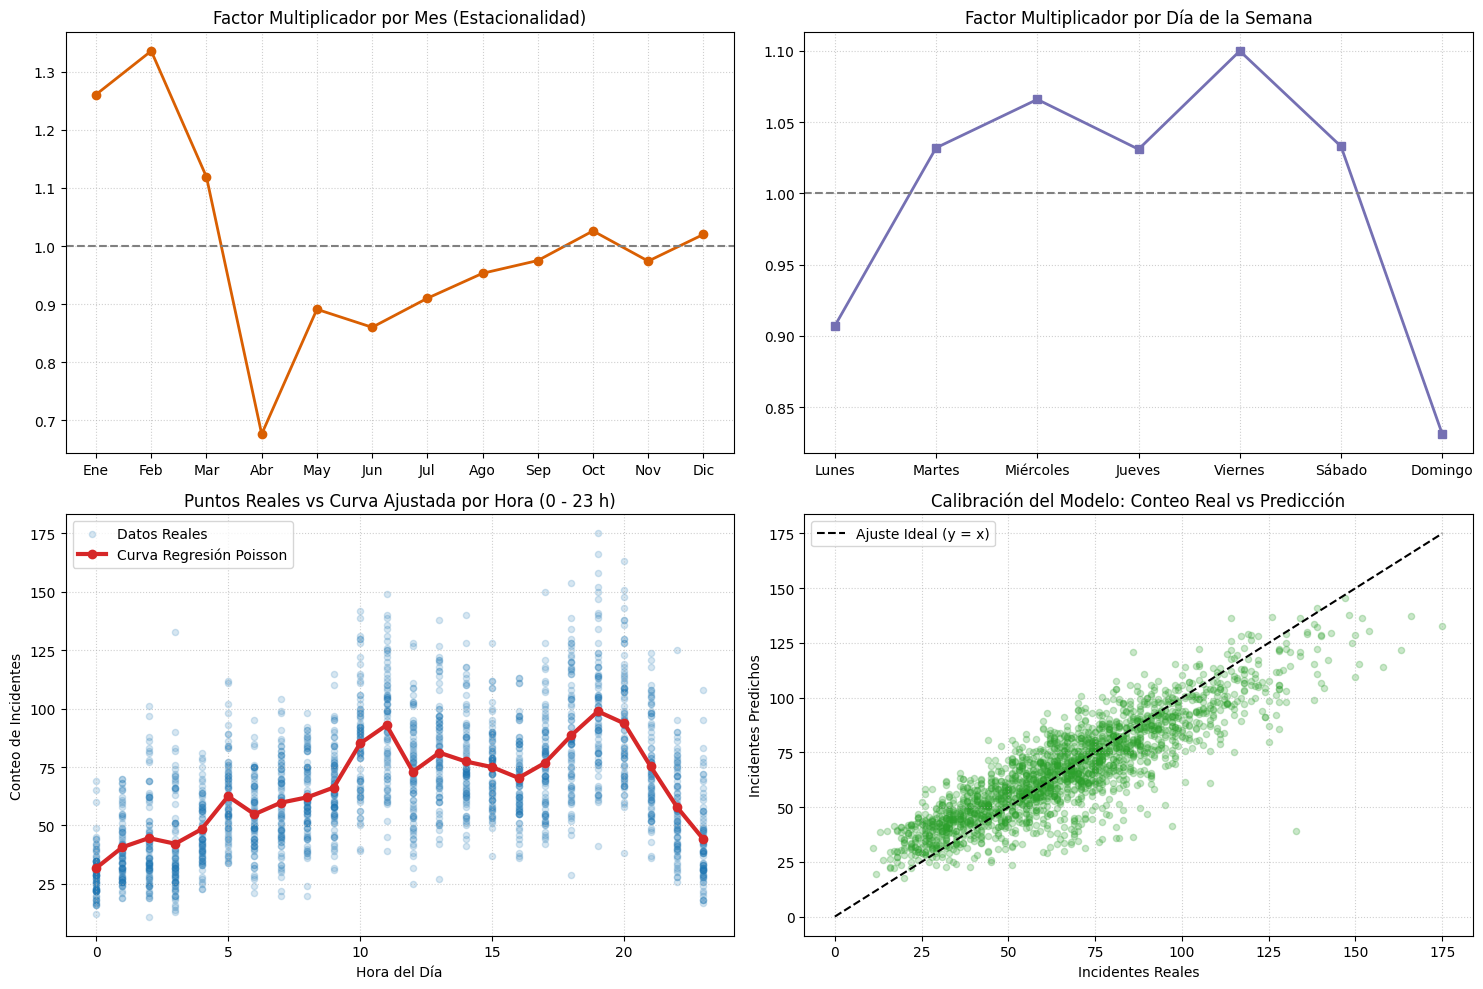

In [ ]:
from sklearn.linear_model import PoissonRegressor
from sklearn.metrics import mean_poisson_deviance, d2_tweedie_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score

# 1. Cargar base de incidentes de la Alcaldía
path_alcaldia = "Data/incidente-reportado-bogota-d-c.csv" # Ajusta al nombre exacto en tu entorno
df_alc = pd.read_csv(path_alcaldia, low_memory=False)

# Filtrar espacio público y últimos años disponibles
cond_sitio = df_alc['CLASE_SITIO'].astype(str).str.contains('VIA|CALLE|ESPACIO PUBLICO', case=False, na=False)
ultimos_anios = sorted(df_alc['AÑO'].dropna().unique())[-3:]
df_alc_clean = df_alc[df_alc['AÑO'].isin(ultimos_anios) & cond_sitio].copy()

# 2. Extraer Mes (1-12), Día de la semana y Hora (0-23)
df_alc_clean['hora_entera'] = pd.to_datetime(df_alc_clean['HORA_HECHO'], errors='coerce').dt.hour
df_alc_clean['fecha_dt'] = pd.to_datetime(df_alc_clean['FECHA_HECHO'], errors='coerce')
df_alc_clean['mes_num'] = df_alc_clean['fecha_dt'].dt.month

if df_alc_clean['mes_num'].isna().sum() > 0:
    mapa_m = {'ene':1,'feb':2,'mar':3,'abr':4,'may':5,'jun':6,'jul':7,'ago':8,'sep':9,'oct':10,'nov':11,'dic':12}
    df_alc_clean['mes_num'] = df_alc_clean['mes_num'].fillna(df_alc_clean['MES'].astype(str).str.lower().str[:3].map(mapa_m))

df_temp = df_alc_clean.dropna(subset=['mes_num', 'hora_entera', 'DIA_SEMANA']).copy()
df_temp['mes_num'] = df_temp['mes_num'].astype(int)
df_temp['hora_entera'] = df_temp['hora_entera'].astype(int)
df_temp['DIA_SEMANA'] = df_temp['DIA_SEMANA'].str.strip().str.capitalize()

# 3. Agregar conteos por celda (Mes, Día, Hora) y codificar One-Hot
agregado_temporal = df_temp.groupby(['mes_num', 'DIA_SEMANA', 'hora_entera']).size().reset_index(name='conteo_delitos')
X_temp = pd.get_dummies(agregado_temporal[['mes_num', 'DIA_SEMANA', 'hora_entera']].astype(str), prefix=['mes', 'dia', 'hora'], dtype=float)
y_temp = agregado_temporal['conteo_delitos']

# 4. Entrenar Modelo Lineal Generalizado: Regresión de Poisson
modelo_poisson = PoissonRegressor(alpha=0.1, max_iter=300)
modelo_poisson.fit(X_temp, y_temp)
agregado_temporal['prediccion_poisson'] = modelo_poisson.predict(X_temp)

# 5. Evaluación de Métricas del Modelo
y_real, y_pred = y_temp.values, agregado_temporal['prediccion_poisson'].values
cv_scores = cross_val_score(modelo_poisson, X_temp, y_real, cv=KFold(n_splits=5, shuffle=True, random_state=42), scoring='neg_mean_poisson_deviance')

df_metricas_glm = pd.DataFrame([
    {"Métrica": "D² Score (Pseudo-R² Poisson)", "Valor": round(d2_tweedie_score(y_real, y_pred, power=1), 4)},
    {"Métrica": "Desvianza Media de Poisson", "Valor": round(mean_poisson_deviance(y_real, y_pred), 4)},
    {"Métrica": "Desvianza Validación Cruzada (5-Fold)", "Valor": round(-cv_scores.mean(), 4)},
    {"Métrica": "R² Ordinario", "Valor": round(r2_score(y_real, y_pred), 4)},
    {"Métrica": "MAE (Error Absoluto Medio)", "Valor": round(mean_absolute_error(y_real, y_pred), 2)},
    {"Métrica": "RMSE", "Valor": round(np.sqrt(mean_squared_error(y_real, y_pred)), 2)}
])
print("--- Métricas de Desempeño de la Regresión Temporal de Poisson ---")
display(df_metricas_glm)

# 6. Extraer Factores Multiplicativos Normalizados
df_coefs = pd.DataFrame({'feature': X_temp.columns, 'mult': np.exp(modelo_poisson.coef_)})

def extraer_factor(prefijo):
    sub = df_coefs[df_coefs['feature'].str.startswith(prefijo)].copy()
    sub['clave'] = sub['feature'].str.replace(prefijo, '')
    sub['factor'] = (sub['mult'] / sub['mult'].mean()).round(3)
    return dict(zip(sub['clave'], sub['factor']))

factores_mes = extraer_factor('mes_')
factores_dia = extraer_factor('dia_')
factores_hora = extraer_factor('hora_')

# 7. Gráficas: Efectos Multiplicativos y Ajuste de Puntos Reales vs Curva de Regresión
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Panel 1: Meses
meses_nombres = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
vals_mes = [factores_mes.get(str(m), 1.0) for m in range(1, 13)]
axes[0, 0].plot(meses_nombres, vals_mes, marker='o', color='#d95f02', linewidth=2)
axes[0, 0].axhline(1.0, color='gray', linestyle='--')
axes[0, 0].set_title("Factor Multiplicador por Mes (Estacionalidad)")
axes[0, 0].grid(True, linestyle=':', alpha=0.6)

# Panel 2: Días
orden_d = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
vals_dia = [factores_dia.get(d, 1.0) for d in orden_d]
axes[0, 1].plot(orden_d, vals_dia, marker='s', color='#7570b3', linewidth=2)
axes[0, 1].axhline(1.0, color='gray', linestyle='--')
axes[0, 1].set_title("Factor Multiplicador por Día de la Semana")
axes[0, 1].grid(True, linestyle=':', alpha=0.6)

# Panel 3: Nube de Puntos Observados vs Curva de Regresión por Hora
axes[1, 0].scatter(agregado_temporal['hora_entera'], agregado_temporal['conteo_delitos'], alpha=0.18, color='#1f77b4', s=20, label='Datos Reales')
curva_h = agregado_temporal.groupby('hora_entera')['prediccion_poisson'].mean()
axes[1, 0].plot(curva_h.index, curva_h.values, color='#d62728', linewidth=3, marker='o', label='Curva Regresión Poisson')
axes[1, 0].set_title("Puntos Reales vs Curva Ajustada por Hora (0 - 23 h)")
axes[1, 0].set_xlabel("Hora del Día")
axes[1, 0].set_ylabel("Conteo de Incidentes")
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle=':', alpha=0.6)

# Panel 4: Calibración Global Real vs Predicho
axes[1, 1].scatter(y_real, y_pred, alpha=0.25, color='#2ca02c', s=20)
max_v = max(y_real.max(), y_pred.max())
axes[1, 1].plot([0, max_v], [0, max_v], 'k--', linewidth=1.5, label='Ajuste Ideal (y = x)')
axes[1, 1].set_title("Calibración del Modelo: Conteo Real vs Predicción")
axes[1, 1].set_xlabel("Incidentes Reales")
axes[1, 1].set_ylabel("Incidentes Predichos")
axes[1, 1].legend()
axes[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Unificado

In [50]:
import json

# 1. Construir lista de los ~1,100 sectores urbanos con su clúster delictivo (k=7)
sectores_lista = []
for idx, row in gdf_urbano.iterrows():
    sectores_lista.append({
        "id_sector": str(row.get('SCANCOD', idx)),
        "nombre_barrio": str(row.get('CMNOMSCAT', 'SECTOR URBANO')),
        "lat": round(float(row['lat']), 5),
        "lon": round(float(row['lon']), 5),
        "cluster_id": int(row['cluster_delictivo']),
        "score_base": float(row['score_base_cluster']),
        "metricas_historicas": {
            "hurtos": int(row['hurtos_totales']),
            "homicidios": int(row['homicidios_totales']),
            "lesiones": int(row['lesiones_totales'])
        }
    })

# 2. Consolidar los 3 modelos en un único esquema JSON
modelo_unificado = {
    "metadata": {
        "ciudad": "Bogotá D.C.",
        "arquitectura": "Inferencia Offline en Cliente Móvil (Kotlin/Jetpack Compose)",
        "modelos": {
            "espacial": "K-Means sobre Densidad y Tipología Delictiva (k=7, Davies-Bouldin=1.0024)",
            "demografico": "Clasificador Naive Bayes (filtrado por Chi-Cuadrado e Información Mutua)",
            "temporal": "GLM Regresión de Poisson (D2=0.7087, Mes-Día-Hora)"
        }
    },
    "modelo_demografico": {
        "multiplicador_sexo": mult_sexo_dict,
        "multiplicador_ciclo_vital": mult_edad_dict
    },
    "modelo_temporal": {
        "factor_mes": factores_mes,
        "factor_dia": factores_dia,
        "factor_hora": factores_hora
    },
    "sectores_urbanos": sectores_lista
}

# 3. Guardar archivo definitivo para colocar en app/src/main/res/raw/
nombre_archivo_json = "modelo_seguridad_bogota.json"
with open(nombre_archivo_json, "w", encoding="utf-8") as f:
    json.dump(modelo_unificado, f, ensure_ascii=False, indent=2)

tamano_kb = len(json.dumps(modelo_unificado)) / 1024
print(f"Archivo '{nombre_archivo_json}' generado exitosamente ({tamano_kb:.1f} KB).")
print(f"Total de sectores catastrales indexados: {len(sectores_lista)}")

Archivo 'modelo_seguridad_bogota.json' generado exitosamente (208.1 KB).
Total de sectores catastrales indexados: 1049
